# Luck-corrected switching headroom on BBOB with GP and PFN surrogates

## Description

**Question.** On standard noise-free benchmarks (COCO/BBOB), with a GP and with the frozen PFN as surrogate, is there **luck-corrected headroom** for switching acquisition functions within a run? That is: does a non-anticipating switching rule beat the tuned best static arm B\*, beyond what an equal-arms null gets? Issue #8.

**Why.** On the PFN's own prior the gain is mixed. The switching pilot (`runs/switching/pilot_20261021-152818`, not snapshotted) shows privileged headroom over B\* (+37% / +36% / +11% at d = 2 / 4 / 6), but a belief controller that loses to B\* (issue #6). The predecessor found no robust gain at all. Meanwhile the literature reports gains from adapting or combining acquisition functions on BBOB and real benchmarks:
- SAWEI adapts EI's exploration weight on noise-free BBOB (Benjamins et al. 2023, arXiv:2306.04262);
- GP-Hedge (arXiv:1009.5419);
- HEBO's acquisition ensemble (arXiv:2012.03826);
- LMABO (arXiv:2602.07904).

Those studies use GP surrogates on functions the surrogate does not model exactly. This experiment moves our luck-controlled design to that setting. It runs both surrogates on the same tasks, so that a GP-only gain can be told apart from a gain that switching has in general.

**Setup.**
- **Tasks.** BBOB f1–f24 (`ioh`, domain [−5, 5]^d mapped to [0, 1]^d), d ∈ {2, 5}. A task is (function, instance, repetition). Repetitions of one instance differ only in the initial design (its shift is keyed by the task seed).
  - *split 0 (selection)*: instance 1, 2 repetitions → 48 tasks/d.
  - *split 1 (evaluation)*: instances 2–5, 2 repetitions → 192 tasks/d (sized by cost: a timing probe on 24 tasks at d = 5 took 274 s (GP) and 173 s (PFN) per privileged member, so the confirm runs fit in about 3 h of ulysses time).

  Nothing is selected on split 1. f is reported as f − f_opt, so f\* = 0 exactly. Regret is log10(regret + 1e-8); 1e-8 is COCO's final target.
- **Budget.** n_init = 2d (scrambled Sobol), T = 10d steps, 5 decisions (every 2d steps). The context is ≤ 60 points: in range for pfn_large (n ≤ 100, d ≤ 6).
- **Surrogates.** Both see y only through its ranks in the current context, a copula transform:
  - **GP**: BoTorch's default single-task GP written out batched. Matérn-5/2 ARD kernel, dimension-scaled LogNormal lengthscale prior, MAP-II refit at every step, on z = Φ⁻¹(rank-uniform y).
  - **PFN**: pfn_large on u = (rank + ½)/n. The marginal of the PFN's training y is Uniform(0, 1) by construction (global ECDF), so u is on the scale it was trained on.

  Neither can use f_opt (ranks are shift-invariant).
- **Arms (K = 6).** ei, pi0.01, ucb0.9, ucb0.99, mes, mean, with the same definitions for both surrogates:
  - the GP uses the closed-form Gaussian versions;
  - the PFN uses the bar distribution.

  ES (alpha-PFN) is left out; its static performance is under question in #6. The candidate set is shared, with CRN per (task, step, replicate): 1024 shifted Sobol points + 3 × 64 incumbent perturbations. Rollouts use 512 + 3 × 32.
- **Methods (per surrogate and d).**
  - `static`: all 6 arms, B\*@0 and random search.
  - `privileged`: the rollout controller. At each decision, R = 8 rollouts per arm on fresh nuisance, each running the arm for one segment and then B\* to the horizon on the true function. It executes the arm with the best mean rollout value. This is one-step policy improvement over B\*, with task knowledge; its gain is unbiased by construction.
  - `equal_arms`: the null control. The same controller over 6 copies of B\*, each restricted to its own random half of the candidates. Its gain over the static B\*@0 must be 0.
- **Not run.** The `belief` controller. Its fantasies live on the per-context rank scale, which has no inverse beyond the observed range, and its value (min fantasised y) is under review in #6. A positive result here is therefore a *ceiling* (switching with task knowledge), not yet a learnable policy.
- **Stages.**
  - `pilot` = selection on split 0 (static only, both surrogates, both d). B\* per (surrogate, d) is the arm with the lowest mean final log10 regret; ties go to the portfolio order. GO if all members are DONE and B\* is defined.
  - `confirm` = evaluation on split 1. One sweep per surrogate, with `task.base_by_d` from the pilot.
- **Numerics.** fp32 (`task.tf32=false`), seed 0, one nuisance stream.

**What to look for.**
- **Primary.** Per surrogate and d: the paired gain of `ctrl:privileged` over static B\* (1 − geometric-mean ratio of final regrets, 95% bootstrap CI over tasks), next to the null's gain over B\*@0.
- **Secondary.**
  1. *How flat is the top:* every static arm vs B\* on split 1 (re-measures the selection), and GP-B\* vs PFN-B\* (which surrogate is better at all).
  2. *Per-function static choice (no switching).* For each function, choose the arm on split 0 (instance 1) and score it on split 1 against the global B\*. This is the value of knowing the problem class, deferred idea 2 and SAWEI's claim. If it is large while switching gains little, the headroom is problem-dependent, not state-dependent.
  3. Gains by BBOB function group (separable 1–5, low/moderate conditioning 6–9, high conditioning 10–14, multimodal with adequate structure 15–19, weak structure 20–24).
  4. Regret curves.
  5. Which arms the controller picks per decision.
  6. Power: MDE at 80% from the per-task sd.

**GO / NO-GO** (per surrogate; `analysis/bo.py::headroom_verdict`, fixed before any run):
- **INVALID** if the null's CI excludes 0 at any d.
- **GO** (luck-corrected headroom detected) if the privileged gain over B\* is ≥ 10% with its CI above 0 at ≥ 1 d, and its point estimate is > 0 at the other d.
- **NO-GO** if the privileged CI upper bound is < 10% at both d. Even with task knowledge, one-step switching then gains less than 10%.
- **INCONCLUSIVE** otherwise.

Reading across surrogates:
- GO for the GP but not for the PFN: the literature's gains come from surrogate misspecification, which a better surrogate removes.
- GO for both: switching has headroom off the prior that our in-prior tests miss.
- NO-GO for both: on noise-free BBOB at this budget, a single tuned arm is as good as one-step switching with task knowledge. Noise (#9) is then the next candidate.

**Limits.**
- Noise-free functions only.
- d ∈ {2, 5}, budget 12d.
- For the PFN, BBOB is off-prior and the rank transform is a modelling choice, not part of the trained model.
- The GP refits from the prior's mode with 100 Adam steps (not L-BFGS); hyperparameters are not shared across steps.
- One-step lookahead over a fixed base: a lower bound on optimal switching, but only with task knowledge (no belief controller).
- One nuisance seed. 24 functions is a small population: per-group results are descriptive only.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.bo import arm_table, final, headroom_verdict, mde_gain, paired_gain, regrets, tasks_for_mde

PILOT = "results/bbob_switching/pilot_20261022-144551"  # selection: split 0, static, both surrogates
CONFIRM = {"gp": "results/bbob_switching/confirm_20261022-145708", "pfn": "results/bbob_switching/confirm_20261023-075829"}  # split 1
GROUPS = {"separable": range(1, 6), "low cond.": range(6, 10), "high cond.": range(10, 15),
          "multimodal": range(15, 20), "weak structure": range(20, 25)}
GROUP_OF = {f: g for g, fs in GROUPS.items() for f in fs}


def column(snap, key):
    """A config value per member: a varying column of runs, or the sweep's constant."""
    return snap.runs[key] if key in snap.runs else pd.Series(snap.constants[key], index=snap.runs.index)


def load(snap):
    """Final and per-step regrets with surrogate, d, fid, instance per row (f* = 0 for BBOB)."""
    runs = snap.runs.assign(d=column(snap, "task.d"), surrogate=column(snap, "task.surrogate"),
                            method=column(snap, "task.method")).set_index("member")
    reg = regrets(snap.table("best"), snap.table("fstar"), runs["d"], eps=1e-8)
    ids = snap.table("tasks").drop_duplicates(["member", "seed"]).set_index(["member", "seed"])[["fid", "instance", "rep"]]
    reg = reg.join(ids, on=["member", "seed"]).assign(surrogate=lambda x: x.member.map(runs.surrogate),
                                                       method=lambda x: x.member.map(runs.method))
    return reg, runs


pilot = load_snapshot(PILOT)
show_header(pilot)
conf = {s: load_snapshot(p) for s, p in CONFIRM.items()}
for s in conf.values():
    show_header(s)

## How it was run

```bash
just sweep detached pilot experiment=bbob_switching task.split=0 task.method=static task.surrogate=gp,pfn task.d=2,5
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261022-144551` |
| commit | `135eb56e9d71` (tag `sweep/bbob_switching/pilot_20261022-144551`) |
| backend / host | detached / ulysses |
| ran | 2026-10-22T14:45:52 → 2026-10-22T14:48:10 |
| members | 4: 4 done |
| compute | 2.2 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/bbob_switching.yaml`):

```yaml
# @package _global_
# Luck-corrected switching headroom on BBOB with GP and PFN surrogates (issue #8).
# Pre-registration: notebooks/04_2026-10-22_bbob_switching.ipynb.
# pilot (selection, split 0 = instance 1):  task.method=static task.split=0 task.surrogate=gp,pfn task.d=2,5
# confirm (evaluation, split 1 = instances 2, 3): task.split=1 task.surrogate=gp,pfn task.d=2,5
#   task.method=static,privileged,equal_arms  with base_by_surrogate/arms from the pilot's selection
defaults:
  - override /task: bo

task:
  benchmark: bbob
  surrogate: gp
  split: 0
  method: static
  arms: [ei, pi0.01, ucb0.9, ucb0.99, mes, mean]
  base: ei
  null_reference: false
  eps: 1.0e-8           # BBOB regrets reach 1e-8 (COCO's final target); f* = 0 exactly
  rollout_candidates: {n_sobol: 512, n_local: 32, local_sigmas: [0.01, 0.05, 0.2]}  # rollouts only
```

**Varying** (4 configurations):

| task.d | task.surrogate |
|---|---|
| 2 | gp |
| 5 | gp |
| 2 | pfn |
| 5 | pfn |

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  alpha: alpha_pes_large
  arms: '["ei", "pi0.01", "ucb0.9", "ucb0.99", "mes", "mean"]'
  base: ei
  bbob.fids: '[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
    20, 21, 22, 23, 24]'
  bbob.instances_by_split.0: '[1]'
  bbob.instances_by_split.1: '[2, 3, 4, 5]'
  bbob.instances_by_split.2: '[6]'
  bbob.reps: 2
  benchmark: bbob
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 512
  device: cuda
  eps: 1.0e-08
  gp_fit_iters: 100
  method: static
  n_init_per_d: 2
  n_rollouts: 8
  n_tasks: 100
  name: bo
  null_k: 6
  null_reference: false
  pfn: pfn_large
  random_search: true
  rollout_candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  rollout_candidates.n_local: 32
  rollout_candidates.n_sobol: 512
  segment_per_d: 2
  split: 0
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  task_offset: 0
  tf32: false
```

## How it was run

```bash
just sweep detached confirm experiment=bbob_switching task.split=1 task.surrogate=gp task.null_reference=true 'task.base_by_d={2:ucb0.9,5:ucb0.9}' 'task.arms_by_d={2:[ucb0.9,ei,pi0.01,ucb0.99,mes,mean],5:[ucb0.9,ei,pi0.01,ucb0.99,mes,mean]}' task.method=static,privileged,equal_arms task.d=2,5
```

|  |  |
|---|---|
| stage | confirm |
| sweep | `confirm_20261022-145708` |
| commit | `63900a28b7bf` (tag `sweep/bbob_switching/confirm_20261022-145708`) |
| backend / host | detached / ulysses |
| ran | 2026-10-22T14:57:10 → 2026-10-22T16:00:51 |
| members | 6: 6 done |
| compute | 1.1 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/bbob_switching.yaml`):

```yaml
# @package _global_
# Luck-corrected switching headroom on BBOB with GP and PFN surrogates (issue #8).
# Pre-registration: notebooks/04_2026-10-22_bbob_switching.ipynb.
# pilot (selection, split 0 = instance 1):  task.method=static task.split=0 task.surrogate=gp,pfn task.d=2,5
# confirm (evaluation, split 1 = instances 2, 3): task.split=1 task.surrogate=gp,pfn task.d=2,5
#   task.method=static,privileged,equal_arms  with base_by_surrogate/arms from the pilot's selection
defaults:
  - override /task: bo

task:
  benchmark: bbob
  surrogate: gp
  split: 0
  method: static
  arms: [ei, pi0.01, ucb0.9, ucb0.99, mes, mean]
  base: ei
  null_reference: false
  eps: 1.0e-8           # BBOB regrets reach 1e-8 (COCO's final target); f* = 0 exactly
  rollout_candidates: {n_sobol: 512, n_local: 32, local_sigmas: [0.01, 0.05, 0.2]}  # rollouts only
```

**Varying** (6 configurations):

| task.d | task.method |
|---|---|
| 2 | static |
| 5 | static |
| 2 | privileged |
| 5 | privileged |
| 2 | equal_arms |
| 5 | equal_arms |

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  alpha: alpha_pes_large
  arms: '["ei", "pi0.01", "ucb0.9", "ucb0.99", "mes", "mean"]'
  arms_by_d.2: '["ucb0.9", "ei", "pi0.01", "ucb0.99", "mes", "mean"]'
  arms_by_d.5: '["ucb0.9", "ei", "pi0.01", "ucb0.99", "mes", "mean"]'
  base: ei
  base_by_d.2: ucb0.9
  base_by_d.5: ucb0.9
  bbob.fids: '[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
    20, 21, 22, 23, 24]'
  bbob.instances_by_split.0: '[1]'
  bbob.instances_by_split.1: '[2, 3, 4, 5]'
  bbob.instances_by_split.2: '[6]'
  bbob.reps: 2
  benchmark: bbob
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 512
  device: cuda
  eps: 1.0e-08
  gp_fit_iters: 100
  n_init_per_d: 2
  n_rollouts: 8
  n_tasks: 100
  name: bo
  null_k: 6
  null_reference: true
  pfn: pfn_large
  random_search: true
  rollout_candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  rollout_candidates.n_local: 32
  rollout_candidates.n_sobol: 512
  segment_per_d: 2
  split: 1
  surrogate: gp
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  task_offset: 0
  tf32: false
```

## How it was run

```bash
just sweep detached confirm experiment=bbob_switching task.split=1 task.surrogate=pfn task.null_reference=true 'task.base_by_d={2:ucb0.99,5:ucb0.99}' 'task.arms_by_d={2:[ucb0.99,ei,pi0.01,ucb0.9,mes,mean],5:[ucb0.99,ei,pi0.01,ucb0.9,mes,mean]}' task.method=static,privileged,equal_arms task.d=2,5
```

|  |  |
|---|---|
| stage | confirm |
| sweep | `confirm_20261023-075829` |
| commit | `63900a28b7bf` (tag `sweep/bbob_switching/confirm_20261023-075829`) |
| backend / host | detached / ulysses |
| ran | 2026-10-23T07:58:30 → 2026-10-23T09:05:17 |
| members | 6: 6 done |
| compute | 1.1 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/bbob_switching.yaml`):

```yaml
# @package _global_
# Luck-corrected switching headroom on BBOB with GP and PFN surrogates (issue #8).
# Pre-registration: notebooks/04_2026-10-22_bbob_switching.ipynb.
# pilot (selection, split 0 = instance 1):  task.method=static task.split=0 task.surrogate=gp,pfn task.d=2,5
# confirm (evaluation, split 1 = instances 2, 3): task.split=1 task.surrogate=gp,pfn task.d=2,5
#   task.method=static,privileged,equal_arms  with base_by_surrogate/arms from the pilot's selection
defaults:
  - override /task: bo

task:
  benchmark: bbob
  surrogate: gp
  split: 0
  method: static
  arms: [ei, pi0.01, ucb0.9, ucb0.99, mes, mean]
  base: ei
  null_reference: false
  eps: 1.0e-8           # BBOB regrets reach 1e-8 (COCO's final target); f* = 0 exactly
  rollout_candidates: {n_sobol: 512, n_local: 32, local_sigmas: [0.01, 0.05, 0.2]}  # rollouts only
```

**Varying** (6 configurations):

| task.d | task.method |
|---|---|
| 2 | static |
| 5 | static |
| 2 | privileged |
| 5 | privileged |
| 2 | equal_arms |
| 5 | equal_arms |

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  alpha: alpha_pes_large
  arms: '["ei", "pi0.01", "ucb0.9", "ucb0.99", "mes", "mean"]'
  arms_by_d.2: '["ucb0.99", "ei", "pi0.01", "ucb0.9", "mes", "mean"]'
  arms_by_d.5: '["ucb0.99", "ei", "pi0.01", "ucb0.9", "mes", "mean"]'
  base: ei
  base_by_d.2: ucb0.99
  base_by_d.5: ucb0.99
  bbob.fids: '[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
    20, 21, 22, 23, 24]'
  bbob.instances_by_split.0: '[1]'
  bbob.instances_by_split.1: '[2, 3, 4, 5]'
  bbob.instances_by_split.2: '[6]'
  bbob.reps: 2
  benchmark: bbob
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 512
  device: cuda
  eps: 1.0e-08
  gp_fit_iters: 100
  n_init_per_d: 2
  n_rollouts: 8
  n_tasks: 100
  name: bo
  null_k: 6
  null_reference: true
  pfn: pfn_large
  random_search: true
  rollout_candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  rollout_candidates.n_local: 32
  rollout_candidates.n_sobol: 512
  segment_per_d: 2
  split: 1
  surrogate: pfn
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  task_offset: 0
  tf32: false
```

## Selection (split 0)

B\* per (surrogate, d): the lowest mean final log10 regret over the 48 selection tasks (pre-registered rule).

In [ ]:
reg0, _ = load(pilot)
fin0 = pd.concat([final(g).assign(surrogate=s) for s, g in reg0.groupby("surrogate")], ignore_index=True)
sel = pd.concat([arm_table(g.drop(columns="surrogate")).assign(surrogate=s) for s, g in fin0.groupby("surrogate")])
BSTAR = {(s, d): g.loc[g.arm != "random"].sort_values("mean_log_regret").arm.iloc[0] for (s, d), g in sel.groupby(["surrogate", "d"])}
display(sel.pivot_table(index="arm", columns=["surrogate", "d"], values="mean_log_regret").round(2))
print("B*:", BSTAR)

surrogate    gp         pfn      
d             2     5     2     5
arm                              
ei         0.29  1.21 -0.06  1.12
mean       0.50  0.89  0.92  2.00
mes        0.38  1.25  0.15  1.22
pi0.01     0.34  1.14  0.11  1.11
random     1.20  2.22  1.20  2.22
ucb0.9     0.14  0.81  0.00  1.11
ucb0.99    0.16  0.85 -0.13  1.03

B*: {('gp', 2): 'ucb0.9', ('gp', 5): 'ucb0.9', ('pfn', 2): 'ucb0.99', ('pfn', 5): 'ucb0.99'}


## Results (split 1)

All methods of one surrogate ran on the same tasks (same split, task list, nuisance streams); both surrogates' sweeps use the same task list, so they pair too.

In [ ]:
regs = {s: load(snap)[0] for s, snap in conf.items()}
reg1 = pd.concat(regs.values(), ignore_index=True)
fins = {s: final(r).merge(r.drop_duplicates(["d", "arm", "seed"])[["d", "arm", "seed", "fid"]], on=["d", "arm", "seed"]) for s, r in regs.items()}
DS = sorted(reg1.d.unique())
for s, f in fins.items():
    print(s, "tasks per (d, arm):", f.groupby(["d", "arm"]).size().unique(), "| arms:", sorted(f.arm.unique()))

gp tasks per (d, arm): [192] | arms: ['ctrl:equal_arms', 'ctrl:privileged', 'ei', 'mean', 'mes', 'pi0.01', 'random', 'ucb0.9', 'ucb0.99', 'ucb0.9@0']
pfn tasks per (d, arm): [192] | arms: ['ctrl:equal_arms', 'ctrl:privileged', 'ei', 'mean', 'mes', 'pi0.01', 'random', 'ucb0.9', 'ucb0.99', 'ucb0.99@0']


### Primary comparison and verdict

Gain over the static B\* (1 − geometric-mean ratio of final regrets, paired over tasks, 95% bootstrap CI). The null (`equal_arms`) is compared with its static counterpart `B*@0`.

In [ ]:
rows = []
for s, f in fins.items():
    for d in DS:
        b = BSTAR[(s, d)]
        for method, ref in [("ctrl:privileged", b), ("ctrl:equal_arms", f"{b}@0")]:
            if method in set(f.loc[f.d == d, "arm"]):
                rows.append({"surrogate": s, "method": method, **paired_gain(f, d, method, ref)})
primary = pd.DataFrame(rows)
primary["mde80"] = [mde_gain(sd, n) for sd, n in zip(primary.sd_log_ratio, primary.n, strict=True)]
display(primary[["surrogate", "d", "method", "b", "n", "gain", "gain_lo", "gain_hi", "frac_a_better", "frac_tied", "sd_log_ratio", "mde80"]].round(3))
VERDICT = {}
for s in fins:
    p = primary.loc[primary.surrogate == s]
    VERDICT[s] = headroom_verdict(p.loc[p.method == "ctrl:privileged"].to_dict("records"),
                                  p.loc[p.method == "ctrl:equal_arms"].to_dict("records"))
print("pre-registered verdict per surrogate:", VERDICT)

,surrogate,d,method,b,n,gain,gain_lo,gain_hi,frac_a_better,frac_tied,sd_log_ratio,mde80
0,gp,2,ctrl:privileged,ucb0.9,192,0.586,0.459,0.688,0.615,0.078,0.853,0.327
1,gp,2,ctrl:equal_arms,ucb0.9@0,192,-0.050,-0.435,0.220,0.406,0.062,0.930,0.351
2,gp,5,ctrl:privileged,ucb0.9,192,0.188,0.031,0.319,0.568,0.042,0.544,0.224
3,gp,5,ctrl:equal_arms,ucb0.9@0,192,-0.057,-0.209,0.077,0.464,0.047,0.407,0.173
4,pfn,2,ctrl:privileged,ucb0.99,192,0.656,0.513,0.761,0.677,0.057,1.090,0.398
5,pfn,2,ctrl:equal_arms,ucb0.99@0,192,-0.014,-0.284,0.196,0.438,0.120,0.720,0.285
6,pfn,5,ctrl:privileged,ucb0.99,192,0.292,0.178,0.389,0.609,0.052,0.457,0.192
7,pfn,5,ctrl:equal_arms,ucb0.99@0,192,-0.019,-0.167,0.112,0.448,0.052,0.420,0.178


pre-registered verdict per surrogate: {'gp': 'GO', 'pfn': 'GO'}


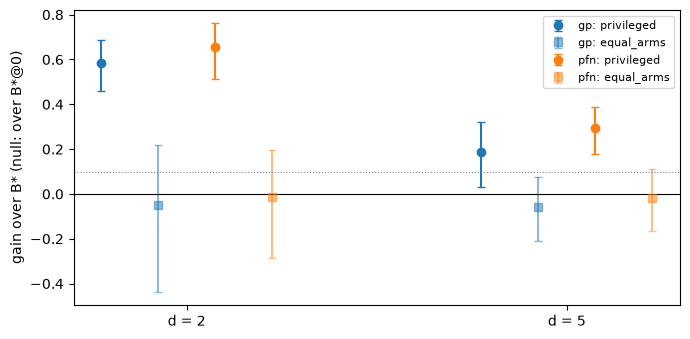

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
labels = [(s, m) for s in fins for m in ("ctrl:privileged", "ctrl:equal_arms")]
for k, (s, m) in enumerate(labels):
    g = primary.loc[(primary.surrogate == s) & (primary.method == m)]
    x = np.array([DS.index(d) for d in g.d]) + (k - 1.5) * 0.15
    ax.errorbar(x, g.gain, yerr=[g.gain - g.gain_lo, g.gain_hi - g.gain], fmt="o" if "priv" in m else "s",
                capsize=3, label=f"{s}: {m.split(':')[1]}", color=f"C{list(fins).index(s)}", alpha=1 if "priv" in m else 0.5)
ax.axhline(0, c="k", lw=0.8); ax.axhline(0.10, c="gray", ls=":", lw=0.8)
ax.set_xticks(range(len(DS)), [f"d = {d}" for d in DS]); ax.set_ylabel("gain over B* (null: over B*@0)")
ax.legend(fontsize=8); fig.tight_layout()

### Static arms: how flat is the top, and which surrogate is better?

Every static arm against its surrogate's B\* on split 1 (the held-out check of the selection), and GP-B\* against PFN-B\* on the same tasks (negative = the GP is worse).

In [ ]:
flat = pd.DataFrame([{"surrogate": s, **paired_gain(f, d, a, BSTAR[(s, d)])} for s, f in fins.items() for d in DS
                     for a in sorted(set(f.loc[f.d == d, "arm"]) - {BSTAR[(s, d)], f"{BSTAR[(s, d)]}@0"}) if not a.startswith("ctrl:")])
display(flat.pivot_table(index="a", columns=["surrogate", "d"], values="gain").round(3))
if {"gp", "pfn"} <= set(fins):  # GP-B* vs PFN-B* on the same tasks (same split, task list, seeds)
    both = pd.concat([f.loc[f.arm == BSTAR[(s, f.d.iloc[0])]].assign(arm=s) for s, f0 in fins.items() for _, f in f0.groupby("d")])
    display(pd.DataFrame([paired_gain(both, d, "gp", "pfn") for d in DS]).round(3))

surrogate      gp             pfn        
d               2       5       2       5
a                                        
ei         -0.783  -1.401  -0.086  -0.365
mean        0.005  -0.079  -5.706  -5.455
mes        -0.611  -1.068  -0.091  -0.141
pi0.01     -0.381  -1.287  -0.309  -0.366
random    -13.690 -23.026 -14.149 -16.906
ucb0.9        NaN     NaN   0.279  -0.058
ucb0.99    -0.386  -0.063     NaN     NaN

,d,a,b,n,gain,gain_lo,gain_hi,sd_log_ratio,frac_a_better,frac_tied
0,2,gp,pfn,192,-0.031,-0.437,0.231,0.964,0.510,0.068
1,5,gp,pfn,192,0.255,0.118,0.373,0.524,0.583,0.047


### Per-function static choice (no switching)

For each function, the arm with the lowest mean final log regret on split 0 (instance 1), scored on split 1 against the global B\*. This is the value of knowing the problem class (SAWEI's "any problem structure" claim), with selection and evaluation on different instances.

In [ ]:
rows = []
for s, f in fins.items():
    for d in DS:
        sel_fd = fin0.loc[(fin0.surrogate == s) & (fin0.d == d) & (fin0.arm != "random")]
        sel_fd = sel_fd.merge(reg0.drop_duplicates(["d", "arm", "seed"])[["d", "arm", "seed", "fid"]], on=["d", "arm", "seed"])
        choice = sel_fd.groupby(["fid", "arm"]).log_regret.mean().unstack().idxmin(1)
        g = f.loc[(f.d == d) & f.arm.isin(set(choice))].copy()
        pick = g.loc[g.arm == g.fid.map(choice)].assign(arm="per-function")
        rows.append({"surrogate": s, **paired_gain(pd.concat([f.loc[f.d == d], pick]), d, "per-function", BSTAR[(s, d)])})
        rows[-1]["n_distinct_choices"] = choice.nunique()
display(pd.DataFrame(rows)[["surrogate", "d", "n", "gain", "gain_lo", "gain_hi", "n_distinct_choices"]].round(3))

,surrogate,d,n,gain,gain_lo,gain_hi,n_distinct_choices
0,gp,2,192,-0.023,-0.271,0.179,6
1,gp,5,192,-0.095,-0.327,0.090,6
2,pfn,2,192,-0.137,-0.496,0.098,6
3,pfn,5,192,-0.240,-0.725,0.038,6


### By function group

Descriptive only (≈ 5 functions × instances × repetitions per group).

In [ ]:
rows = []
for s, f in fins.items():
    for d in DS:
        for grp, fs in GROUPS.items():
            sub = f.loc[f.fid.isin(list(fs))]
            for m in ("ctrl:privileged", "ctrl:equal_arms"):
                ref = BSTAR[(s, d)] + ("@0" if "equal" in m else "")
                rows.append({"surrogate": s, "group": grp, "method": m, **paired_gain(sub, d, m, ref, n_boot=2000)})
grp = pd.DataFrame(rows)
display(grp.pivot_table(index=["method", "group"], columns=["surrogate", "d"], values="gain", sort=False).round(2))

surrogate                         gp         pfn      
d                                  2     5     2     5
method          group                                 
ctrl:privileged separable       0.59  0.01  0.53  0.38
                low cond.       0.64  0.28  0.75  0.24
                high cond.      0.74  0.09  0.85  0.53
                multimodal      0.45  0.35  0.48  0.17
                weak structure  0.43  0.17  0.51  0.02
ctrl:equal_arms separable       0.27 -0.15 -0.13  0.14
                low cond.      -1.62 -0.19  0.12 -0.06
                high cond.      0.39  0.08  0.01 -0.24
                multimodal     -0.17  0.02 -0.40 -0.05
                weak structure -0.13 -0.08  0.24  0.07

### Regret curves

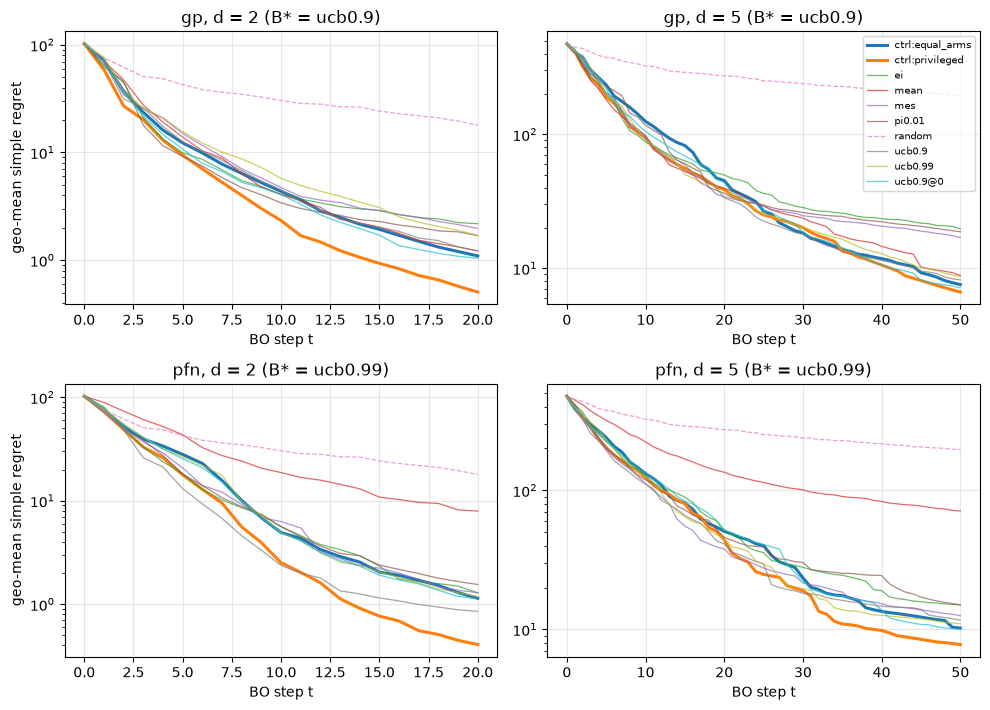

In [ ]:
fig, axes = plt.subplots(len(fins), len(DS), figsize=(5 * len(DS), 3.6 * len(fins)), squeeze=False)
for i, (s, r) in enumerate(regs.items()):
    for j, d in enumerate(DS):
        ax = axes[i, j]
        curves = r.loc[r.d == d].groupby(["arm", "t"]).log_regret.mean().unstack(0)
        for arm in curves.columns:
            style = dict(lw=2.2) if arm.startswith("ctrl:") else dict(lw=0.9, alpha=0.7, ls="--" if arm == "random" else "-")
            ax.plot(curves.index, 10 ** curves[arm], label=arm, **style)
        ax.set_yscale("log"); ax.set_title(f"{s}, d = {d} (B* = {BSTAR[(s, d)]})"); ax.set_xlabel("BO step t"); ax.grid(alpha=0.3)
    axes[i, 0].set_ylabel("geo-mean simple regret")
axes[0, -1].legend(fontsize=7); fig.tight_layout()

### What the privileged controller chooses

Share of tasks choosing each arm per decision (decision j starts at step 2d·j).

In [ ]:
for s, snap in conf.items():
    runs = snap.runs.set_index("member")
    dec = snap.table("decisions").assign(d=lambda x: x.member.map(column(snap, "task.d").set_axis(snap.runs.member)),
                                          method=lambda x: x.member.map(column(snap, "task.method").set_axis(snap.runs.member)))
    share = dec.loc[dec.method == "privileged"].groupby(["d", "decision"]).chosen.value_counts(normalize=True).unstack(fill_value=0)
    print(s); display(share.round(2))

gp


chosen        ei  mean   mes  pi0.01  ucb0.9  ucb0.99
d decision                                           
2 0         0.16  0.20  0.12    0.19    0.17     0.15
  1         0.14  0.21  0.14    0.16    0.22     0.13
  2         0.10  0.27  0.09    0.09    0.30     0.15
  3         0.08  0.27  0.07    0.10    0.32     0.16
  4         0.08  0.38  0.02    0.06    0.38     0.09
5 0         0.14  0.18  0.22    0.12    0.18     0.16
  1         0.08  0.22  0.05    0.13    0.27     0.24
  2         0.06  0.23  0.12    0.08    0.24     0.26
  3         0.07  0.29  0.05    0.09    0.28     0.22
  4         0.06  0.30  0.02    0.05    0.33     0.24

pfn


chosen        ei  mean   mes  pi0.01  ucb0.9  ucb0.99
d decision                                           
2 0         0.15  0.12  0.21    0.13    0.16     0.23
  1         0.17  0.16  0.13    0.14    0.19     0.22
  2         0.12  0.26  0.13    0.08    0.14     0.26
  3         0.08  0.28  0.09    0.10    0.19     0.27
  4         0.07  0.34  0.06    0.05    0.22     0.27
5 0         0.17  0.05  0.19    0.19    0.19     0.21
  1         0.16  0.15  0.14    0.21    0.13     0.22
  2         0.12  0.22  0.13    0.12    0.16     0.24
  3         0.07  0.30  0.14    0.08    0.17     0.24
  4         0.07  0.01  0.08    0.40    0.22     0.22

### Power

In [ ]:
primary.assign(n_for_mde10=[tasks_for_mde(s, 0.10) for s in primary.sd_log_ratio])[["surrogate", "d", "method", "sd_log_ratio", "n", "mde80", "n_for_mde10"]].round(3)

,surrogate,d,method,sd_log_ratio,n,mde80,n_for_mde10
0,gp,2,ctrl:privileged,0.853,192,0.327,2722
1,gp,2,ctrl:equal_arms,0.930,192,0.351,3236
2,gp,5,ctrl:privileged,0.544,192,0.224,1109
3,gp,5,ctrl:equal_arms,0.407,192,0.173,621
4,pfn,2,ctrl:privileged,1.090,192,0.398,4449
5,pfn,2,ctrl:equal_arms,0.720,192,0.285,1944
6,pfn,5,ctrl:privileged,0.457,192,0.192,784
7,pfn,5,ctrl:equal_arms,0.420,192,0.178,662


## How this compares with SAWEI

SAWEI (Benjamins et al. 2023, arXiv:2306.04262; read in full, v3) adapts the weight α of Weighted EI during a run. It starts at α = 0.5 (= EI). Whenever the upper-bound regret (UBR) stalls (the smoothed gradient falls within ε = 0.1 of its maximum), it moves α by Δα = 0.1, *against* the current search attitude.

**Its protocol.**
- 24 noise-free BBOB functions in **8D**, 3 instances, 10 seeds;
- budget 24 initial + 256 BO evaluations;
- SMAC's GP (BlackBoxFacade), with SMAC's local + random acquisition search.

**Its baselines.** EI, PI, LCB; WEI with α ∈ {0, 0.5, 1}; step schedules; EI→PI switches at 25/50/75% of the budget; the Gutmann–Sobester pulse; and GP-Hedge with 9 arms.

**Its statistics.**
- The IQM over seeds per function, then ranks, then the IQM of ranks.
- No significance tests, no paired-design statement, and no gain numbers: the claim is "ranks among the first".
- There is **no luck control**: no null with equivalent arms, and no static per-function α (oracle or held-out). Their ablation is tuned on the same functions it is reported on.

**What our design adds.**
- (i) A null that gets the same selection opportunity as the controller.
- (ii) Paired CRN across methods.
- (iii) B\* selected on held-out instances.
- (iv) A per-function static choice made on held-out instances. It tells *problem-dependent* headroom (what a good per-problem α gives) apart from *state-dependent* headroom (what adaptation within a run gives). SAWEI cannot tell these apart.

**What it doesn't share with SAWEI.**
- Our controller has task knowledge (privileged rollouts), so it is a ceiling, not a deployable rule.
- Our budget is 12d, not 35d.
- Our arms are 6 distinct acquisitions, not one continuous α.

## Observations

Numbers are from the snapshots above (selection `pilot_20261022-144551`; confirm `confirm_20261022-145708` (GP) and `confirm_20261023-075829` (PFN); all members DONE: 4/4, 6/6, 6/6). n = 192 tasks per (surrogate, d) on split 1.

1. **Luck-corrected headroom is clearly detected, for both surrogates.** The privileged controller beats the static B\* by:
   - GP: **+59%** [+46, +69] at d = 2 and **+19%** [+3, +32] at d = 5;
   - PFN: **+66%** [+51, +76] at d = 2 and **+29%** [+18, +39] at d = 5.

   The equal-arms null gets the same selection opportunity *and* the same extra true-f evaluations in its rollouts. It gains −5% / −6% (GP) and −1% / −2% (PFN), every CI includes 0. So the gain comes from the *diversity of the arms*, not from selection luck or from the rollouts' extra information. The regret curves separate from about t ≈ 2d onwards and the gap widens late.
2. **The headroom is state-dependent, not problem-dependent.** A single arm chosen *per function* on instance 1 and scored on instances 2–5 does **not** beat the global B\*: −2% / −10% (GP), −14% / −24% (PFN), all CIs include 0. Knowing the problem class buys nothing here. Choosing the arm by state within a run buys a lot. SAWEI's design cannot separate these two sources (see above); ours can, and it attributes the gain to the within-run state.
3. **What the controller does.** At decision 0 the choices are spread across all arms (5–23% each). Over the run, the share of the pure-exploitation arm `mean` grows (GP d = 2: 20% → 38%; PFN d = 2: 12% → 34%) and `mes`/`ei` fade. That is an explore → exploit drift, but no single schedule: at d = 5 for the PFN the last decision prefers `pi0.01` (40%) over `mean` (1%). It is consistent with the flat-on-average but heterogeneous static arms.
4. **No single arm dominates, and EI is not the best arm.** Against B\* on split 1, EI loses 78% / 140% (GP) and 9% / 37% (PFN). The top is flat but not stable: for the PFN at d = 2, `ucb0.9` beats the selected `ucb0.99` by 28% on split 1. The selection rule picked the best arm on split 0, but the ranking at the top doesn't transfer. The PFN's `mean` arm fails off the prior (−571% / −546%). On the rank scale, pure exploitation by the PFN stalls.
5. **GP vs PFN.** At d = 2 the two B\*s are tied (GP vs PFN −3% [−44, +23]). At d = 5 the GP's B\* is 26% [12, 37] better. So off the prior the GP is the better surrogate at d = 5, yet switching headroom is as large or larger for the PFN. **Headroom is not an artefact of surrogate misspecification:** it appears with both a GP (the literature's setting) and the PFN.
6. **Power.** The per-task sd of the log ratio is 0.46–1.09, so the MDE at 80% is 19–40%. The gains above are far beyond it at d = 2 and above it at d = 5. Ruling out a 10% gain would need ≈ 800–4400 tasks.

**What this changes in the bigger picture.**
- "We can't detect luck-corrected headroom" no longer holds. On BBOB with K = 6 distinct arms and a non-anticipating, null-controlled controller, it is detected with large margins. This repo's own in-prior pilot already pointed the same way: privileged gains of +37 / +36 / +11% at d = 2 / 4 / 6, from `runs/switching/pilot_20261021-152818`, not snapshotted, pilot only.
- The predecessor's null result came from a different design: a hindsight oracle over 4 fixed switch points and 3 arms, minus a null tree. The bottleneck is now **whether the headroom can be found without task knowledge**. In-prior, the belief controller (PFN fantasies, value = min fantasised y) *lost* to B\* (#6). The next question is the value model, not the existence of headroom.

**Caveats.**
- The privileged controller is a ceiling: it uses 48 rollouts per decision on the *true* function.
- Noise-free functions only; d ∈ {2, 5}; budget 12d (regrets are still 1–10 at the end, so BBOB is far from solved at this budget).
- One nuisance seed.
- The PFN reads rank-transformed y, a modelling choice.
- The GP uses an Adam MAP-II fit, not BoTorch's L-BFGS.
- Group-level numbers are descriptive.

## Verdict

Pre-registered rule (`analysis/bo.py::headroom_verdict`):
- **GP: GO.** Privileged ≥ 10% with the CI above 0 at d = 2 (and at d = 5: +19% [+3, +32]); null CIs include 0.
- **PFN: GO.** The same holds at both d.

Recorded with `just decide` on `confirm_20261022-145708` (GP) and `confirm_20261023-075829` (PFN).

Next (not decided here; see the log entry): make the headroom reachable *without* task knowledge.
- Fix the belief controller's value (latent f instead of min fantasised y, #6), run it on the prior and, with a GP, on BBOB.
- In parallel, a learned policy only makes sense once a belief-based controller recovers a sizeable part of this ceiling.